# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

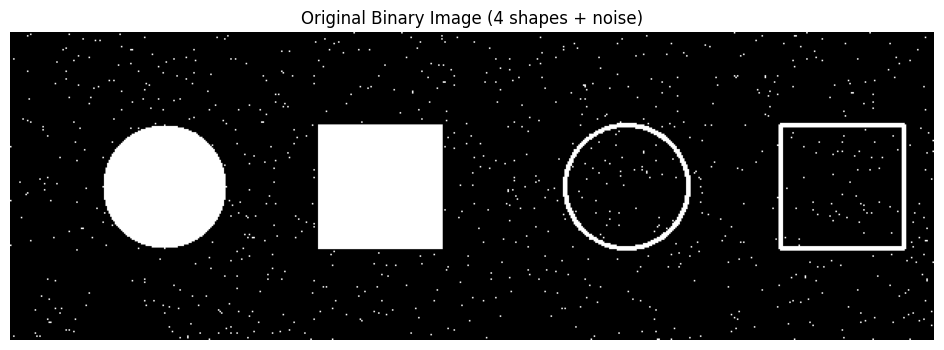

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



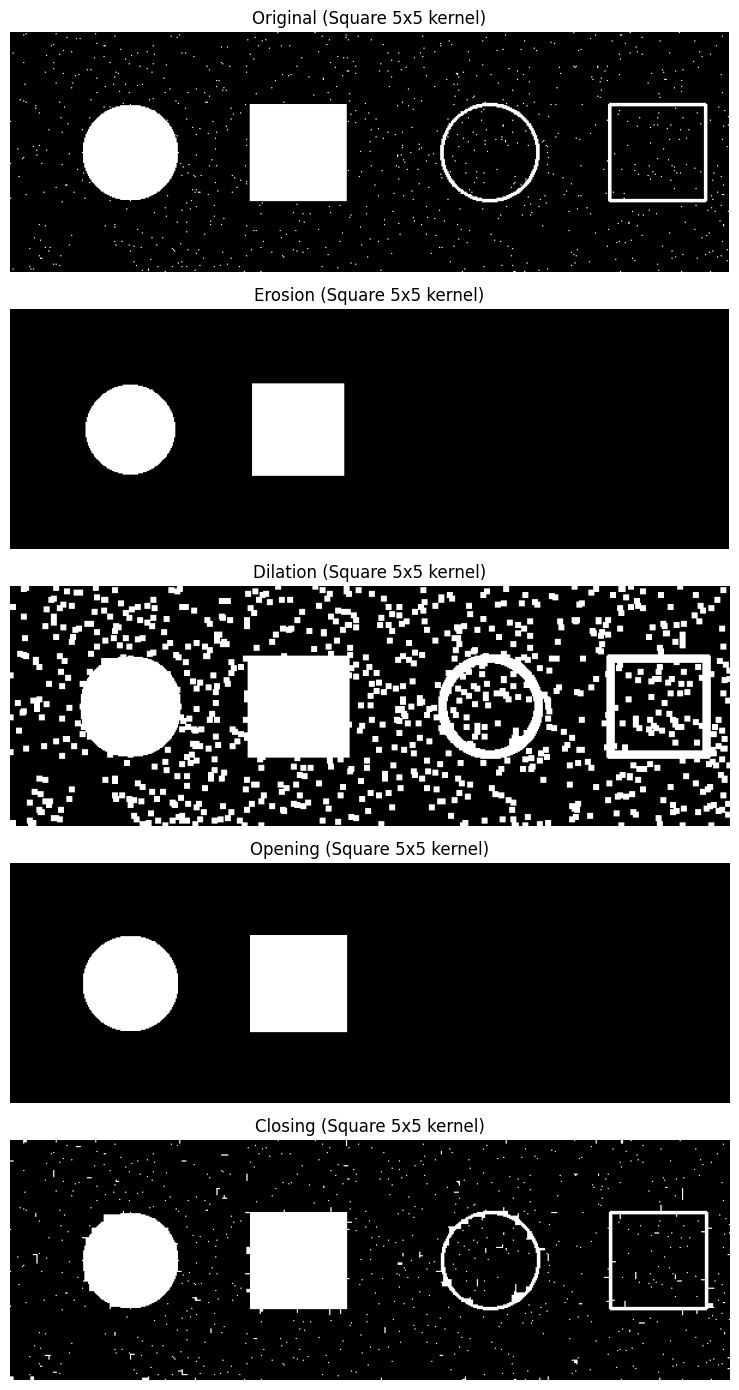

In [4]:
# Apply the four morphological operations using the 5x5 square kernel
erosion  = cv2.erode(image, kernel, iterations=1)
dilation = cv2.dilate(image, kernel, iterations=1)
opening  = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

results_sq = [image, erosion, dilation, opening, closing]
titles = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']

plt.figure(figsize=(12, 14))
for i, (img, t) in enumerate(zip(results_sq, titles)):
    plt.subplot(5, 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f'{t} (Square 5x5 kernel)')
    plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

Circular kernel (radius=5, size 11x11):
[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


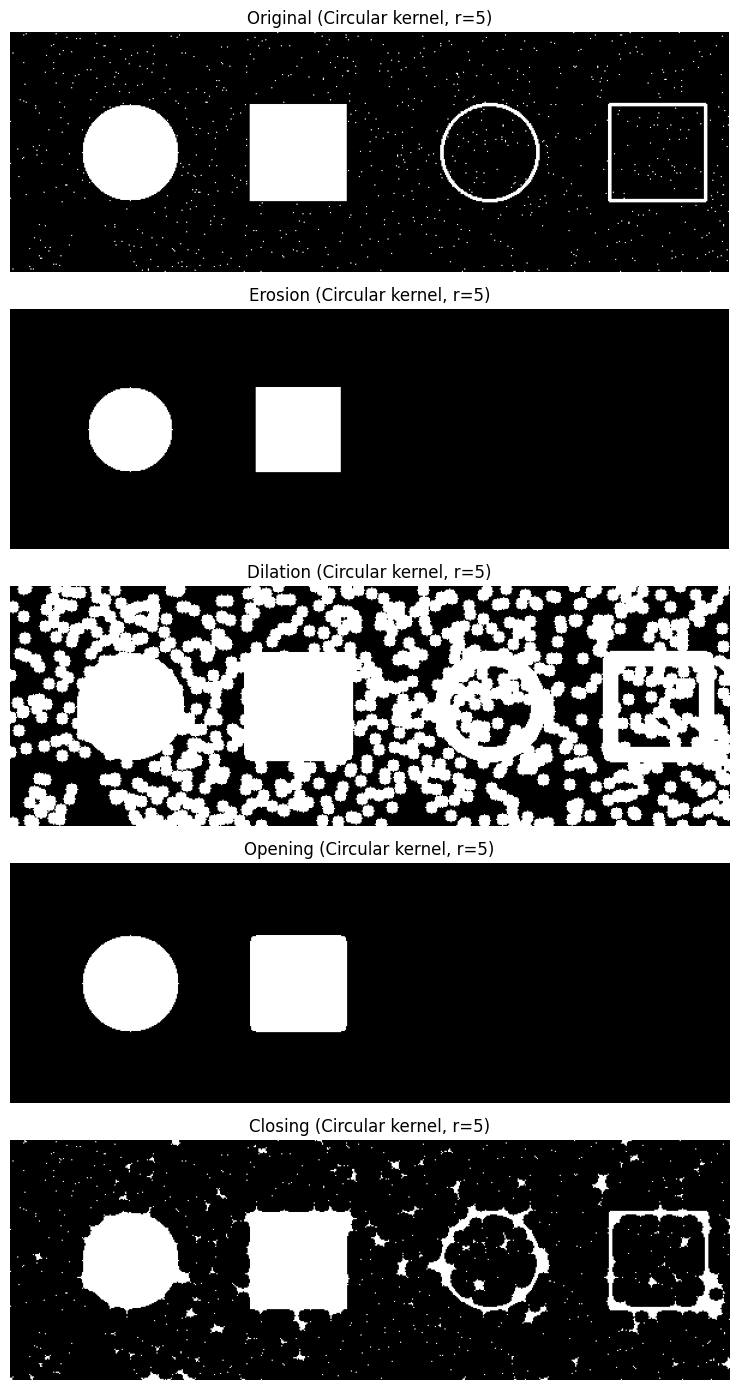

In [6]:
print("Circular kernel (radius=5, size 11x11):")
print(circle_kernel)

# Apply the four morphological operations using the circular kernel
erosion_c  = cv2.erode(image, circle_kernel, iterations=1)
dilation_c = cv2.dilate(image, circle_kernel, iterations=1)
opening_c  = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_c  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

results_c = [image, erosion_c, dilation_c, opening_c, closing_c]

plt.figure(figsize=(12, 14))
for i, (img, t) in enumerate(zip(results_c, titles)):
    plt.subplot(5, 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f'{t} (Circular kernel, r=5)')
    plt.axis('off')
plt.tight_layout()
plt.show()

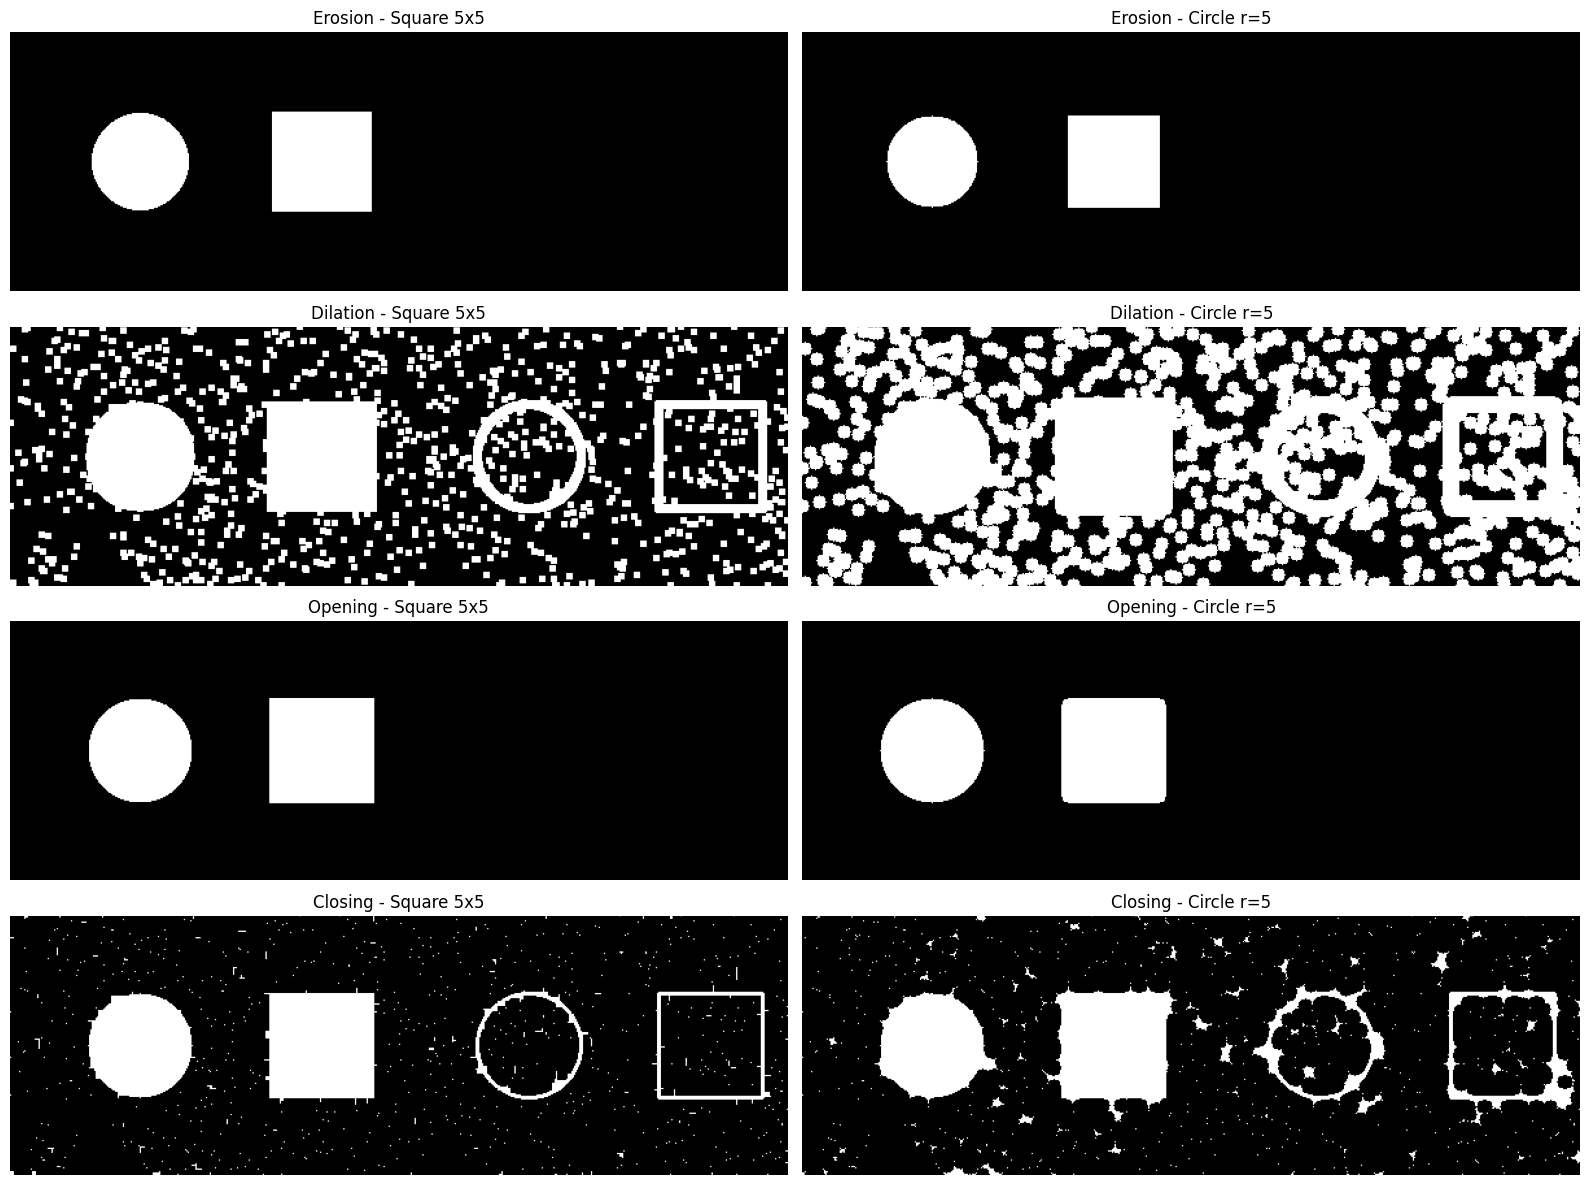

Original  | square:  14165 white px | circle:  14165 white px
Erosion   | square:  10335 white px | circle:   8903 white px
Dilation  | square:  35685 white px | circle:  67938 white px
Opening   | square:  11583 white px | circle:  11547 white px
Closing   | square:  14707 white px | circle:  17834 white px


In [7]:
# Side-by-side comparison: Square (left) vs Circular (right)
plt.figure(figsize=(16, 12))
for i, t in enumerate(titles[1:]):
    plt.subplot(4, 2, 2*i + 1)
    plt.imshow(results_sq[i+1], cmap='gray'); plt.title(f'{t} - Square 5x5'); plt.axis('off')
    plt.subplot(4, 2, 2*i + 2)
    plt.imshow(results_c[i+1], cmap='gray');  plt.title(f'{t} - Circle r=5'); plt.axis('off')
plt.tight_layout()
plt.show()

# Count foreground pixels to quantify the difference
for t, a, b in zip(titles, results_sq, results_c):
    print(f"{t:9s} | square: {np.count_nonzero(a):6d} white px | circle: {np.count_nonzero(b):6d} white px")

## Assessment Task 3 — Difference Between Square vs Circular Kernel



**Answer:**

**1. Shape of the result follows the shape of the kernel.**
- With the **square kernel**, dilation makes objects grow with **sharp, square corners** — the solid circle and the noise specks become slightly "boxy", and every noise pixel turns into a small 5×5 square.
- With the **circular kernel**, dilation grows objects **evenly in all directions**, so edges stay **round and smooth** — the circle stays circular, noise pixels become small round dots, and the rectangle corners become rounded.

**2. Kernel size / strength.**
- The circular kernel has radius 5 (an 11×11 neighborhood), which is larger than the 5×5 square, so its effect is **stronger**: erosion removes more, dilation adds more.
- In erosion, the circular kernel **completely erases the thin hollow circle and hollow rectangle** (line thickness 2 px) and shrinks the solid shapes more. The square kernel also removes the thin outlines but shrinks the solid shapes less.

**3. Opening.**
- Both kernels remove the salt noise, because single noise pixels are smaller than either kernel.
- But both also delete the **hollow shapes**, since their 2-px outlines are thinner than the kernel.
- With the circular kernel, the **rectangle's corners become rounded**, while with the square kernel the rectangle keeps its **sharp corners** (a square fits perfectly into a rectangle corner, a circle does not).

**4. Closing.**
- Closing with the circular kernel **joins nearby noise pixels into larger round blobs** and fills more gaps, because it is larger.
- With the square kernel, the result is closer to the original, with less merging.

**Summary:** The square kernel is directionally biased (it reaches further along the diagonals), so it preserves straight edges and sharp corners — better for rectangular objects. The circular kernel is **isotropic** (same distance in every direction), so it gives smoother, more natural results that preserve round shapes — better for circular objects. The choice of structuring element should match the shape of the objects we want to keep.